In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn

candidate_paths = [
    Path("data/processed/data_logistic_regression.csv"),
    Path("../data/processed/data_logistic_regression.csv"),
]
data_path = next((path for path in candidate_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("data/processed/data_logistic_regression.csv 파일을 찾을 수 없습니다.")

data_frame = pd.read_csv(data_path, header=None)
if data_frame.shape[1] != 9:
    raise ValueError(f"데이터는 9개 열이어야 합니다. 현재 열 개수: {data_frame.shape[1]}")

data = torch.tensor(data_frame.to_numpy(), dtype=torch.float32)
x = data[:, :8]
y = data[:, 8:]

assert x.ndim == 2 and x.shape[1] == 8
assert y.shape == (x.shape[0], 1)


class LogisticRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(8, 1)

    def forward(self, inputs):
        return torch.sigmoid(self.linear(inputs))


criterion = nn.BCELoss()
EPOCHS = 2000
MAIN_LEARNING_RATE = 0.1


def train_model(learning_rate, epochs=EPOCHS):
    torch.manual_seed(42)
    model = LogisticRegression()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    loss_history = []
    accuracy_history = []

    for _ in range(epochs):
        probability = model(x)
        loss = criterion(probability, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            epoch_probability = model(x)
            epoch_loss = criterion(epoch_probability, y)
            epoch_prediction = (epoch_probability >= 0.5).float()
            epoch_accuracy = (epoch_prediction == y).float().mean()
        loss_history.append(epoch_loss.item())
        accuracy_history.append(epoch_accuracy.item())

    return model, loss_history, accuracy_history


## Q1.
---

데이터의 앞 8개 열을 각각 하나의 입력 특성으로 사용하기 때문이며, 따라서 각 샘플은 8개의 특성값으로 모델에 입력됨

---

In [2]:
print(f"전체 데이터 Shape: {tuple(data.shape)}")
print(f"x.shape: {tuple(x.shape)}")
print(f"y.shape: {tuple(y.shape)}")
print("x의 처음 5개 데이터:")
print(x[:5])
print("y의 처음 5개 데이터:")
print(y[:5])

assert x.ndim == 2 and x.shape[1] == 8
assert y.shape == (x.shape[0], 1)


전체 데이터 Shape: (759, 9)
x.shape: (759, 8)
y.shape: (759, 1)
x의 처음 5개 데이터:
tensor([[-0.2941,  0.4874,  0.1803, -0.2929,  0.0000,  0.0015, -0.5312, -0.0333],
        [-0.8824, -0.1457,  0.0820, -0.4141,  0.0000, -0.2072, -0.7669, -0.6667],
        [-0.0588,  0.8392,  0.0492,  0.0000,  0.0000, -0.3055, -0.4927, -0.6333],
        [-0.8824, -0.1055,  0.0820, -0.5354, -0.7778, -0.1624, -0.9240,  0.0000],
        [ 0.0000,  0.3769, -0.3443, -0.2929, -0.6028,  0.2846,  0.8873, -0.6000]])
y의 처음 5개 데이터:
tensor([[0.],
        [1.],
        [0.],
        [1.],
        [0.]])


## Q2.
---

학습이 진행되면서 Loss는 약 `0.7086`에서 `0.4741`로 감소했고, Accuracy는 약 `50.86%`에서 `76.81%`로 상승함

---



학습 Epoch: 2000
학습 Learning Rate: 0.1
최종 Loss: 0.4741
최종 Accuracy: 76.81%


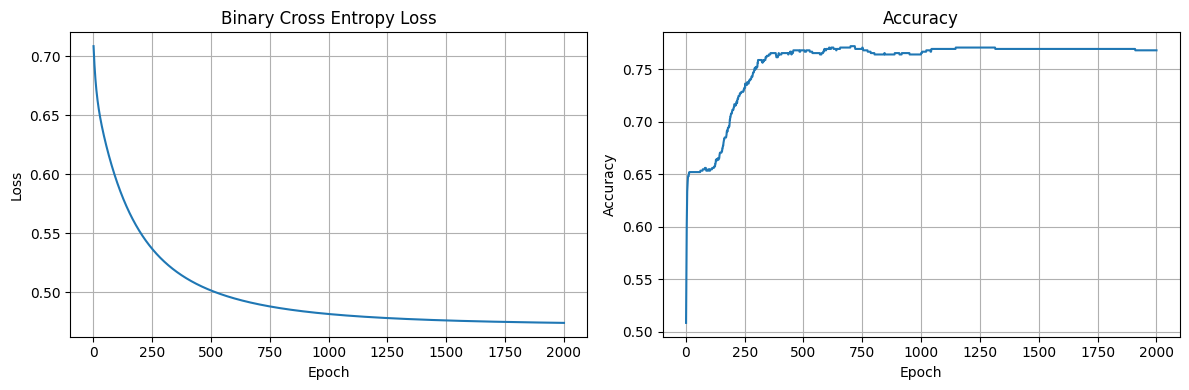

In [3]:
model, loss_history, accuracy_history = train_model(MAIN_LEARNING_RATE)
final_loss = loss_history[-1]
final_accuracy = accuracy_history[-1]
print(f"\n학습 Epoch: {EPOCHS}")
print(f"학습 Learning Rate: {MAIN_LEARNING_RATE}")
print(f"최종 Loss: {final_loss:.4f}")
print(f"최종 Accuracy: {final_accuracy:.2%}")
assert final_accuracy >= 0.75, "Accuracy가 75%에 도달하지 않았습니다. Epoch 또는 Learning Rate를 조정하세요."

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, EPOCHS + 1)
axes[0].plot(epochs, loss_history)
axes[0].set_title("Binary Cross Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)
axes[1].plot(epochs, accuracy_history)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)
plt.tight_layout()
plt.show()


## Q3.
---

Sigmoid 출력은 각 샘플이 Class 1일 확률이고, 최종 Class는 그 확률에 Threshold를 적용해 얻는 값임


Threshold를 변경하면 확률에 따라 0,1의 결과 또한 바뀌게 됨


`이번 데이터에서는 Threshold = 0.3 Accuracy = 74.04%, Threshold 0.5 = Accuracy = 76.81%를 기록함.`

---

In [4]:
with torch.no_grad():
    all_probabilities = model(x)
    first_five_classes = (all_probabilities[:5] >= 0.5).int()

print("\n처음 5개 데이터 예측 (Threshold = 0.5)")
print("Probability    Prediction    Label")
print("----------------------------------")
for probability, prediction, label in zip(all_probabilities[:5], first_five_classes, y[:5]):
    print(f"{probability.item():<14.4f} {prediction.item():<13} {int(label.item())}")

print("\nThreshold별 전체 데이터 Accuracy")
threshold_accuracies = {}
for threshold in (0.3, 0.5):
    predictions = (all_probabilities >= threshold).float()
    accuracy = (predictions == y).float().mean().item()
    threshold_accuracies[threshold] = accuracy
    print(f"{threshold:<12.1f}{accuracy:.2%}")



처음 5개 데이터 예측 (Threshold = 0.5)
Probability    Prediction    Label
----------------------------------
0.3837         0             0
0.9449         1             1
0.1971         0             0
0.9572         1             1
0.1199         0             0

Threshold별 전체 데이터 Accuracy
0.3         74.04%
0.5         76.81%


## Q4 .
---

두 실험 모두 `2000` Epoch를 수행했으며, `0.001`은 최종 Loss `0.6599`, Accuracy `65.22%`였고 `0.1`은 최종 Loss `0.4741`, Accuracy `76.81%`를 기록함


이 데이터와 Epoch 수에서는 μ = `0.1`이 더 빠르게 학습해 더 낮은 Loss와 높은 Accuracy에 도달하였음.

---

In [5]:
print("\nLearning Rate 비교 (동일한 Epoch 수, 각각 새 모델)")
learning_rate_results = {}
for learning_rate in (0.001, 0.1):
    comparison_model, comparison_loss, comparison_accuracy = train_model(learning_rate)
    learning_rate_results[learning_rate] = {
        "loss": comparison_loss[-1],
        "accuracy": comparison_accuracy[-1],
    }
    print(
        f"{learning_rate:<15.3g}"
        f"{comparison_loss[-1]:<15.4f}"
        f"{comparison_accuracy[-1]:.2%}"
    )



Learning Rate 비교 (동일한 Epoch 수, 각각 새 모델)
0.001          0.6599         65.22%
0.1            0.4741         76.81%


## Q5.
---

activate function의 유무
linear regression이 선형결합의 결과를 출력한다면, logistic regression은 해당 선형결합의 결과에 sigmoid라는 activate function를 적용하여 결과를 출력함. 

---

## 결과
---

- Epoch: `2000`
- Learning Rate: `0.1`
- Loss: `0.4741`
- Accuracy: `76.81%`
